In [1]:
# assign directory
import git
from pathlib import Path
import os
ROOT_DIR = Path(git.Repo('.', search_parent_directories=True).working_tree_dir)
os.chdir(os.path.join(ROOT_DIR, 'utilities'))
from transform_audio import *
CWD = os.path.join(ROOT_DIR, 'dataset-preparation', 'audioData', 'accent', 'distribution_comparisons')
os.chdir(CWD)

accent_dir = os.path.join(ROOT_DIR, 'raw-data', 'accent')
transform_dir = os.path.join(accent_dir, 'transforms')

In [2]:
affix = 'stft'
category = 'gender'
df = pd.read_csv(os.path.join(accent_dir, 'full-accent.csv'))
group_map = df.dropna(subset=['filename', 'sex']).set_index('filename')['sex']
group_map.value_counts()

sex
male      809
female    728
Name: count, dtype: int64

In [ ]:
# partition data by group

partitions_dir = os.path.join(CWD, 'partitions', affix, category)
os.makedirs(partitions_dir, exist_ok=True)

valid_groups = [g for g in group_map.unique() if pd.notna(g)]
out_zipfiles = {
    group: zipfile.ZipFile(
        os.path.join(partitions_dir, f'{affix}_{category}_{group}_coefs.npz'), 'w'
    ) for group in valid_groups
}

coefs_npz_path = os.path.join(transform_dir, f'{affix}_coefs.npz')

with np.load(coefs_npz_path, allow_pickle=True) as coefs_npz:
    for file in coefs_npz.files:
        cycle_name = file.rsplit('_', 1)[0]
        
        if cycle_name in group_map:
            group = group_map[cycle_name]
            
            if pd.notna(group) and group in out_zipfiles:
                with out_zipfiles[group].open(file + '.npy', 'w', force_zip64=True) as zipf_entry:
                    np.save(zipf_entry, coefs_npz[file])
        else:

            print(f"Warning: '{cycle_name}' not found in metadata, skipping.")
for zf in out_zipfiles.values():
    zf.close()

In [4]:
# compute pooled bands

subsample_every, batch_size, max_depth = 100, None, 5 # tune these parameters
bands = freq_band_groupings(
    coefs_npz_path,
    subsample_every=subsample_every, 
    batch_size=batch_size,
    max_depth=max_depth,
    presplit_depth=1,
    debug=False
)

In [5]:
def compare_groups(group1, group2, visualize=True):
    group1_coef_bands, group2_coef_bands = (
        group_coefs_by_band(
            load_coefs_by_freq(
                os.path.join(partitions_dir, f'{affix}_{category}_{group}_coefs.npz'),
                subsample_every=subsample_every,
                batch_size=batch_size,
                debug=True
            ), bands
        ) for group in [group1, group2]
    )

    statistics = [ks_2samp(group1_coefs, group2_coefs).statistic
                  for group1_coefs, group2_coefs in zip(group1_coef_bands, group2_coef_bands)]
    
    if visualize:
        plt.figure(figsize=(16, 5))
        plt.bar([f'[{band[0]}, {band[1]})' for band in bands], statistics)
        plt.axhline(.05, ls='--', c='r')
        plt.xlabel('Band index range')
        plt.xticks(rotation=45)
        plt.ylabel('KS statistic')
        plt.title(f'{affix.upper()} distribution comparison between '
                  f'"{category}" partitions: {group1} vs. {group2}')
        plt.show()

    return statistics

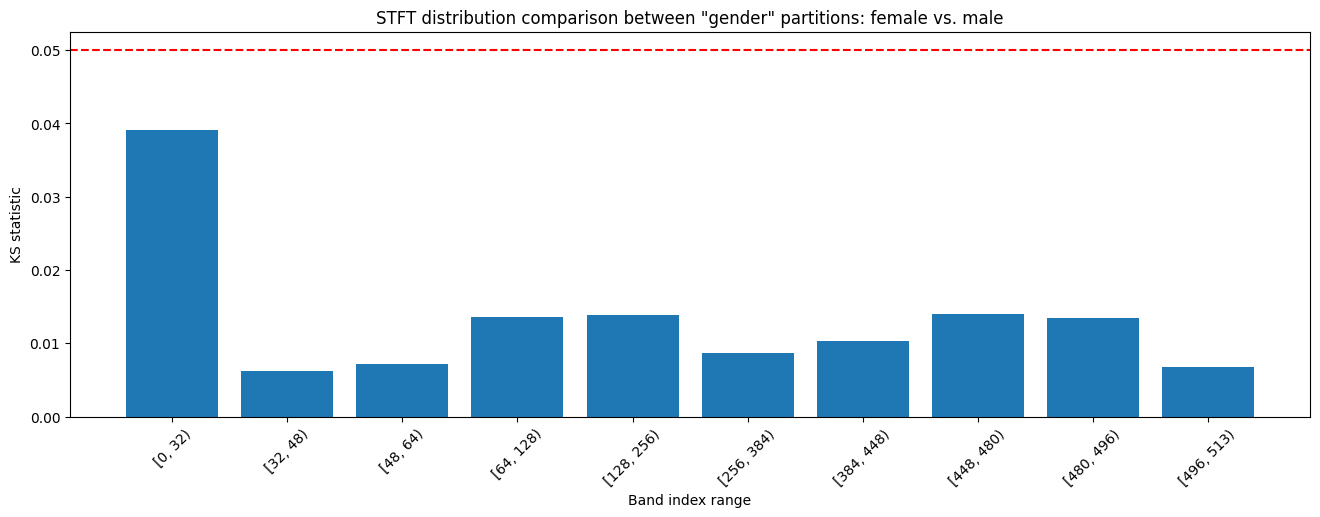

In [6]:
statistics = compare_groups('female', 'male', visualize=True)

In [7]:
# optionally delete partition coefficient archives

for file in Path(partitions_dir).iterdir():
    file.unlink()